## Main pipeline

In [4]:
%load_ext autoreload
%autoreload 2

import polars as pl # use pl.__version__ to check version
import polars.selectors as cs

import pathlib as Path
import matplotlib.pyplot as plt
import numpy as np

import pipeline_funcs as pf   # data loading / cleaning helpers
import visualize as viz       # plotting helpers

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
wd = Path.Path().resolve()
data_dir = Path.Path(f'{wd}/dengue_reporting')
output_dir = Path.Path(f'{wd}/output')

In [6]:
# useful global variables (the ones shared with other notebooks, eg pf.TRAIN_END_YEAR and pf.CODE_TO_UF, are in pipeline_funcs)
SELECTED_STATES = [state for state in pf.FOCUS_STATES if state != "PR"] # PR is dropped, see rainfall_exploratory.ipynb
SELECTED_CODES = [pf.UF_ABBR_TO_CODE[state_abbr] for state_abbr in SELECTED_STATES]
TRAIN_YEARS = [year for year in pf.DEFAULT_YEARS if int(year) <= pf.TRAIN_END_YEAR] # training subset of pf.DEFAULT_YEARS
TEST_YEARS = [int(year) for year in pf.DEFAULT_YEARS if int(year) > pf.TRAIN_END_YEAR] # the test-set MAE is also split by these years

### Read in files
Create a dictionary of Lazyframes so each is accessible by year

In [7]:
lf_dict = pf.load_dengue_data(data_dir)

Read in population estimate data

In [8]:
pop_csv = output_dir / "pop_estimates.csv"
if not pop_csv.exists():
    pf.fetch_population(pop_csv)

pop_lf = pf.load_population(pop_csv)

### Basic data cleaning
Data cleaning applicable to the entire dataset or almost. That is:
- Remove ES state due to system change
- Convert columns starting with "DT_" to date format
- Drop duplicates according to ``NDUPLIC_N``, non-individual notifications using ``TP_NOT`` and non-Brazil cases.
- Keep only confirmed cases: codes 1, 10, 11, 12 in ``CON_CLASSI`` before 2007 and in ``CLASSI_FIN`` from 2007. The pre-2007 column is assumed to use the same codes, which is supported by a similar share of confirmed notifications in both periods (about 52% vs 50%, see `exploratory.ipynb`).

The `null_dict` describes how null values are encoded for different fields. The default one used, based on the metadata PDFs, is in ``pipeline_funcs.py``.

In [9]:
clean_dict = pf.full_basic_clean(lf_dict, drop_nulls=True, select_cols=['SG_UF_NOT', 'DT_NOTIFIC'])

# Trying to fit a model
We start with basic linear regression, since it is highly interpretable, using just the timeseries and a sine term to attempt to account for seasonality. The evaluation metrics I chose to use are:
- **BIC**, because it measures both how well a model performs on the training set and penalizes it for having too many predictors; I don't want to overfit or pointlessly add noise. *Limitation:* it can only be compared between models fitted on exactly the same rows with the same dependent variable, and it says nothing directly about performance on unseen data.
- **Model vs baseline MAE** (the MAE ratio), since it measures performance on the test set (unseen data, which would be key in real-world usage) and tells me whether the model actually adds value compared to just guessing the rate from [lag] months ago. *Limitation:* the test set is only four years (48 months), so a single unusual year can move it a lot (which is why the values for each test year are also shown on the plots), and the ratio depends on how good the baseline is, which itself gets worse as the lag grows.
- **R squared**, because it is an easy-to-read summary, on a 0-1 scale, of how much of the variation in log(rate) over the training years the model explains, so models for the same state can be compared at a glance. *Limitation:* it is in-sample only and never decreases when a predictor is added, so it can't detect overfitting. Here it is also inflated by the lagged rate, since monthly rates are strongly autocorrelated, so a high R squared does not mean that the model beats the naive baseline.

In [10]:
monthly_case_counts = pl.concat(
    [
        pf.cases_per_capita_monthly(lf, pop_lf, year, states=SELECTED_CODES)
        for year, lf in clean_dict.items()
    ],
    how="vertical",
)

In [11]:
# Check the rate and cases are closely correlated
monthly_case_counts.with_columns(
    pl.col("cases").log(),
    pl.col("rate").log(),
).filter(pl.col("SG_UF_NOT") == 23).collect().to_pandas()[["cases", "rate"]].corr()

,cases,rate
cases,1.000000,0.998803
rate,0.998803,1.000000


On the log scale, log(rate) and log(count) differ only by log(population), which changes slowly within a state, so the two are almost perfectly correlated. Can assume that using rates and counts is equivalent, though rates are more comparable so I prefer to use that going forward. I manually checked this by running the models on both counts and cases as well, and did not see much of a difference, as expected. I have not included the code as it's a bit redundant.

In [12]:
def make_global_model_df(monthly_case_counts, global_lag=3, cases=False):
    """Base modelling frame for all states: log_rate, its value global_lag months earlier (log_rate_lag) and year;
    cases=True adds the same for log(cases). Plain logs, so every state-month needs at least one case."""
    # Plain logs, no +1: none of the selected states has a month without cases, so log(rate) and log(cases)
    # are always defined. Some other states do have zero months (eg SC, RS), so fail loudly if one is added
    zero_months = monthly_case_counts.filter(pl.col("cases") == 0).select(pl.len()).collect().item()
    if zero_months > 0:
        raise ValueError(f"{zero_months} state-months have zero cases, so their log is undefined")

    lf = (
        monthly_case_counts
        .sort("SG_UF_NOT", "month")
        .with_columns(pl.col("rate").log().alias("log_rate"))
        .with_columns(
            pl.col("log_rate").shift(global_lag).over("SG_UF_NOT").alias("log_rate_lag"),
            pl.col("month").dt.year().alias("year"),
        )
        .drop_nulls(["log_rate_lag"])
        .drop(["population"])
    )

    if cases:
        lf = (lf.with_columns(pl.col("cases").log().alias("log_cases"))
                .with_columns(pl.col("log_cases").shift(global_lag).over("SG_UF_NOT").alias("log_cases_lag"))
                .drop_nulls(["log_cases_lag"]))

    return lf

In [13]:
model_df = make_global_model_df(monthly_case_counts, cases=True, global_lag=1) # lag chosen after exploration, see below

To account for seasonality, we add a 'season' term based on the month and 'phi' denotes where it is considered to start. This will vary from state to state due to weather differences. ``find_phase`` finds the optimal value for phi for a given state. 

In [14]:
import statsmodels.formula.api as smf
def find_phase(state_data, formula):
    """Try the 12 possible phase shifts (in months) of the sine seasonal term on the training years and
    return the one with the highest R squared."""
    train = state_data.filter(pl.col("year") <= pf.TRAIN_END_YEAR).to_pandas()

    results = []
    for i in range(1, 13):
        phi = 2 * np.pi * i / 12
        train["sin_m"] = np.sin(2 * np.pi * train["month"].dt.month / 12 + phi)
        fit = smf.ols(formula, data=train).fit()
        results.append((i, fit.rsquared))

    best_i, best_r2 = max(results, key=lambda r: r[1])
    print(f"Best R2 with chosen phase = {best_r2}, phase = {2 * np.pi * best_i / 12}")
    return best_i

def run_regression(state_code, global_model_data, formula):
    """Fit an OLS model for one state on the training years, with the sine term at the phase from find_phase.
    Returns (train, test, fit)."""
    state_data = (global_model_data.filter(pl.col("SG_UF_NOT") == state_code).collect())

    phase = find_phase(state_data, formula)

    state_model_data = state_data.with_columns((2 * np.pi * pl.col("month").dt.month().add(phase) / 12).sin().alias("sin_m"))
    train = state_model_data.filter(pl.col("year") <= pf.TRAIN_END_YEAR).to_pandas()
    test = state_model_data.filter(pl.col("year") > pf.TRAIN_END_YEAR).to_pandas()

    fit = smf.ols(formula, data=train).fit()

    return train, test, fit

In [15]:
def compute_regression_mae(fit, test, pop_lf, _state_code=None, per=100000, method='rate', average=True):
    """Test-set mean absolute error (MAE) of the model and of the baseline (guessing the value from [lag] months ago),
    computed per test year. average=True: (model_mae, baseline_mae), the mean over the years; False: {year: (model, baseline)}."""
    if method not in ['rate', 'cases']:
        raise ValueError("Invalid method")

    fac = 1
    cases_predictor = "log_rate_lag"
    if method == 'cases':
        # cases are scaled to a rate with the state's median population, so the MAE is comparable with method='rate'
        state_pop = pop_lf.filter(pl.col("SG_UF_NOT") == _state_code).median().collect()["population"].item()
        fac = per/state_pop
        cases_predictor = "log_cases_lag"

    actual = test[method].to_numpy() * fac
    pred_cases = np.exp(fit.predict(test).to_numpy()) * fac # back from the log scale
    baseline_cases = np.exp(test[cases_predictor].to_numpy()) * fac # the value [lag] months ago

    # absolute error in every test month, then the MAE within each test year
    model_errors, baseline_errors = np.abs(actual - pred_cases), np.abs(actual - baseline_cases)
    years = test["year"].to_numpy()
    mae_by_year = {int(year): (model_errors[years == year].mean(), baseline_errors[years == year].mean())
                   for year in np.unique(years)}
    if not average:
        return mae_by_year
    # with the same number of months in every test year this equals the MAE over all test months
    return np.mean([m for m, _ in mae_by_year.values()]), np.mean([b for _, b in mae_by_year.values()])

def compare_models(models, pop_lf=pop_lf, methods=None):
    """One row per model in models = {name: (train, test, fit)}: n_train, n_params, in-sample r2 and bic, and the test-set
    MAEs and mae_ratio (< 1 = beats the baseline), overall and per test year. methods = {name: 'rate' or 'cases'}."""
    methods = methods or {}
    rows = []
    for model_name, (train, test, fit) in models.items():
        state_codes = test["SG_UF_NOT"].unique()
        if len(state_codes) != 1:
            raise ValueError(f"{model_name}: test data contains {len(state_codes)} states, expected exactly 1")
        state_code = int(state_codes[0])
        method = methods.get(model_name, "rate")

        model_mae, baseline_mae = compute_regression_mae(fit, test, pop_lf, _state_code=state_code, method=method)
        mae_by_year = compute_regression_mae(fit, test, pop_lf, _state_code=state_code, method=method, average=False)
        rows.append({
            "state code": state_code,
            "model": model_name,
            "n_train": int(fit.nobs),
            # includes the intercept; a phase chosen by find_phase is an extra hidden parameter, not counted here (or in the BIC)
            "n_params": len(fit.params),
            # r2 and bic: only comparable between models with the same dependent variable and the same training rows
            "r2": fit.rsquared,
            "bic": fit.bic,
            "model_mae": model_mae,
            "baseline_mae": baseline_mae,
            "mae_ratio": model_mae / baseline_mae,
            # the model MAE and the ratio in each test year separately, to show how much the overall values depend on single years
            **{f"model_mae_{year}": model for year, (model, _) in mae_by_year.items()},
            **{f"mae_ratio_{year}": model / baseline for year, (model, baseline) in mae_by_year.items()},
        })
    return pl.DataFrame(rows).sort("state code", "model")

# one marker shape per test year, for the yearly values (MAE ratio, model MAE) on the plots
TEST_YEAR_MARKERS = dict(zip(TEST_YEARS, ["o", "s", "^", "D", "v", "P"]))

def plot_yearly_values(ax, x, rows, prefix, color, spread=0.3):
    """Each test year's value (the <prefix>_<year> columns of rows, eg prefix="mae_ratio") as translucent markers
    at positions x, shifted slightly per year so they don't overlap."""
    for offset, year in zip(np.linspace(-spread / 2, spread / 2, len(TEST_YEARS)), TEST_YEARS):
        ax.scatter(np.asarray(x) + offset, rows[f"{prefix}_{year}"], marker=TEST_YEAR_MARKERS[year], color=color,
                   alpha=0.35, s=25, linewidths=0)

def add_year_legend(ax, **legend_kwargs):
    """Legend for the markers from plot_yearly_values (grey, since colour is used for other things)."""
    handles = [plt.Line2D([], [], marker=marker, linestyle="none", color="grey", alpha=0.6, label=str(year))
               for year, marker in TEST_YEAR_MARKERS.items()]
    return ax.legend(handles=handles, title="Test year", **legend_kwargs)

In [16]:
# repeat the experiments and store the results
seasonal_results = dict()
for i in range(len(SELECTED_STATES)):
    state_name = SELECTED_STATES[i]
    state = pf.UF_ABBR_TO_CODE[state_name]
    print(f"\n ---- Running models for state {state_name} ---- \n")
    seasonal_results[f"{state_name} without seasonal term"] = run_regression(state, model_df, formula="log_rate ~ log_rate_lag" )
    seasonal_results[f"{state_name} with seasonal term"] = run_regression(state, model_df, formula="log_rate ~ log_rate_lag + sin_m")


 ---- Running models for state CE ---- 

Best R2 with chosen phase = 0.7672117045347093, phase = 0.5235987755982988
Best R2 with chosen phase = 0.8627043066524794, phase = 3.141592653589793

 ---- Running models for state PB ---- 

Best R2 with chosen phase = 0.7628245249596413, phase = 0.5235987755982988
Best R2 with chosen phase = 0.8571594275696501, phase = 3.141592653589793

 ---- Running models for state SP ---- 

Best R2 with chosen phase = 0.81745249853602, phase = 0.5235987755982988
Best R2 with chosen phase = 0.9597839617111642, phase = 1.0471975511965976

 ---- Running models for state RJ ---- 

Best R2 with chosen phase = 0.8804272824246357, phase = 0.5235987755982988
Best R2 with chosen phase = 0.9355868360286882, phase = 1.0471975511965976


In [17]:
seasonal_vs_base_comparison = compare_models(seasonal_results)
seasonal_vs_base_comparison

state code,model,n_train,n_params,r2,bic,model_mae,baseline_mae,mae_ratio
i64,str,i64,i64,f64,f64,f64,f64,f64
23,"""CE with seasonal term""",178,3,0.862704,208.837967,4.804683,9.483257,0.506649
23,"""CE without seasonal term""",178,2,0.767212,297.638847,8.822086,9.483257,0.93028
25,"""PB with seasonal term""",178,3,0.857159,267.40692,5.562554,7.397375,0.751963
25,"""PB without seasonal term""",178,2,0.762825,352.483799,6.645011,7.397375,0.898293
33,"""RJ with seasonal term""",178,3,0.935587,301.590636,3.703359,4.162868,0.889617
33,"""RJ without seasonal term""",178,2,0.880427,406.520842,3.939618,4.162868,0.946371
35,"""SP with seasonal term""",178,3,0.959784,222.618401,13.070312,15.126586,0.864062
35,"""SP without seasonal term""",178,2,0.817452,486.705146,15.673893,15.126586,1.036182


An MAE ratio of less than 1 means the model adds value beyond just the baseline (see comments in MAE function for further explanation of why). It seems that for the states CE and SP there is the biggest improvement in MAE when adding the seasonality term. This is quite interesting because CE and PB, and SP and RJ, are geographically close to each other, so one might expect them to display similar improvement patterns. 

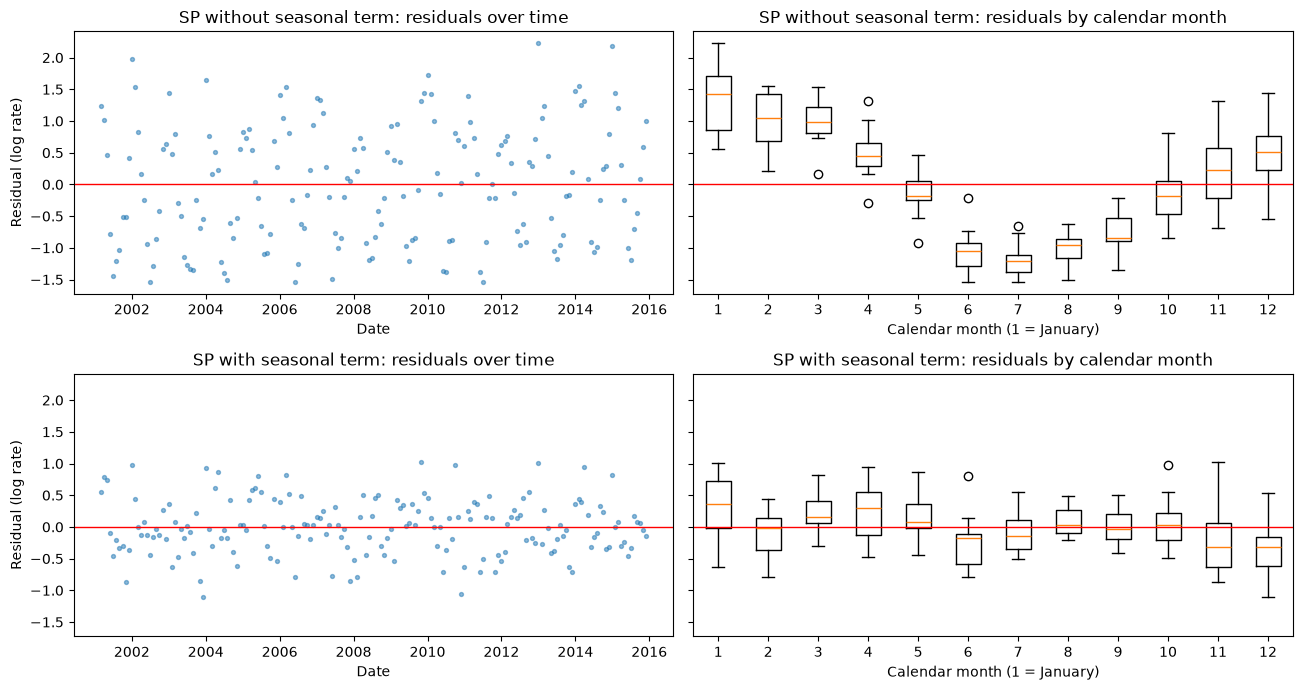

In [18]:
# some example residual plots for SP in the seasonal vs non-seasonal model
train_seasonal, test_seasonal, fit_seasonal = seasonal_results['SP with seasonal term']
train_base, test_base, fit_base = seasonal_results['SP without seasonal term']

# The two diagnostics that show what the seasonal term is meant to fix, for both models:
#   left:  residuals over time - seasonality the model misses shows up as a regular yearly wave
#   right: residuals by calendar month - if seasonality is captured, every month's box should sit around 0
# sharey=True puts all panels on the same scale, so the size of the residuals can be compared between models
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
for row, (label, train, fit) in enumerate([
    ("without seasonal term", train_base, fit_base),
    ("with seasonal term", train_seasonal, fit_seasonal),
]):
    ax_time, ax_month = axes[row]
    ax_time.scatter(train["month"], fit.resid, s=8, alpha=0.5)
    ax_time.set(title=f"SP {label}: residuals over time", xlabel="Date", ylabel="Residual (log rate)")
    ax_month.boxplot([fit.resid[train["month"].dt.month == m] for m in range(1, 13)])
    ax_month.set(title=f"SP {label}: residuals by calendar month", xlabel="Calendar month (1 = January)")
    for ax in (ax_time, ax_month):
        ax.axhline(0, color="red", linewidth=1)
plt.tight_layout()
plt.show()

Something I realized at this point is that rather than estimating the phase 'manually' as before, it is possible to get the regression to estimate it by using the sin(A + B) identity. This isn't likely to change model performance but can potentially save computation time, so from now on we take this approach. I did try adding another two sinusoidal terms to account for faster seasonal variations, but this didn't make a difference in performance (and ended up sometimes making things worse) so I left it out.

In [19]:
def run_improved_regression(state_code, global_model_data, formula):
    """Fit an OLS model for one state on the training years, with sin and cos seasonal terms (so OLS picks the
    phase itself). Returns (train, test, fit)."""
    print("Running regression for state ", state_code)
    state_data = (global_model_data.filter(pl.col("SG_UF_NOT") == state_code).collect())

    # Seasonal terms with no phase: OLS weights sin and cos itself
    angle = 2 * np.pi * pl.col("month").dt.month() / 12
    state_model_data = state_data.with_columns(
        angle.sin().alias("sin_m"),
        angle.cos().alias("cos_m"),
        #(2 * angle).sin().alias("sin2_m"), turned out to be unnecessary and of no added value
        #(2 * angle).cos().alias("cos2_m"),
    )
    train = state_model_data.filter(pl.col("year") <= pf.TRAIN_END_YEAR).to_pandas()
    test = state_model_data.filter(pl.col("year") > pf.TRAIN_END_YEAR).to_pandas()

    fit = smf.ols(formula, data=train).fit()

    return train, test, fit

## Finding lag term
An important part of timeseries prediction is the temporal lag used (how far back we look to make our predictions). To find the best lag for the lagged rate term, I tried some different values. 

I started with a lag of 3 months for the cases as it was reported by [Lowe et al. (2021)](https://researchonline.lshtm.ac.uk/id/eprint/4660590/1/2021_lowe_LancetPlanHealth.pdf) to be associated with the highest risk for dengue at temperatures that correspond to typical temperatures for these states (20-25 degrees). There's some wiggle room here, lag of 2-4 months could also work according to this same paper, and they used temperature to assess the relationship to risk, but given that this has obviously seasonal variation, I decided to look at lag values of 1-4 to see what happens (didn't explore too many as this would take a long time)

In [20]:
lags_tested = range(1, 5)

# BIC sums the fit over every training row, so it's only comparable between models fitted on the same rows.
# A longer lag loses more months at the start of the series, so every lag is restricted to the months that
# the longest lag still has.
common_start = (
    make_global_model_df(monthly_case_counts, cases=True, global_lag=max(lags_tested))
    .select(pl.col("month").min())
    .collect()
    .item()
)

lag_results = dict()
for lag in lags_tested:
    for state in SELECTED_STATES:
        lag_model_df = (
            make_global_model_df(monthly_case_counts, cases=True, global_lag=lag) # own name, so model_df keeps the lag chosen above
            .filter(pl.col("month") >= common_start)
        )
        state_code = pf.UF_ABBR_TO_CODE[state]
        lag_results[f"Lag {lag} months in {state}"] = run_improved_regression(state_code, lag_model_df, formula="log_rate ~ log_rate_lag + sin_m + cos_m")

Running regression for state  23
Running regression for state  25
Running regression for state  35
Running regression for state  33
Running regression for state  23
Running regression for state  25
Running regression for state  35
Running regression for state  33
Running regression for state  23
Running regression for state  25
Running regression for state  35
Running regression for state  33
Running regression for state  23
Running regression for state  25
Running regression for state  35
Running regression for state  33


In [21]:
lag_comparison = compare_models(lag_results)
lag_comparison

state code,model,n_train,n_params,r2,bic,model_mae,baseline_mae,mae_ratio
i64,str,i64,i64,f64,f64,f64,f64,f64
23,"""Lag 1 months in CE""",172,4,0.861703,208.069908,4.727267,9.483257,0.498486
23,"""Lag 2 months in CE""",172,4,0.691993,345.793183,7.299403,16.128391,0.452581
23,"""Lag 3 months in CE""",172,4,0.579724,399.248818,9.020289,21.705889,0.415569
23,"""Lag 4 months in CE""",172,4,0.502443,428.281971,10.14484,24.956313,0.406504
25,"""Lag 1 months in PB""",172,4,0.862858,255.686368,6.182871,7.397375,0.83582
…,…,…,…,…,…,…,…,…
33,"""Lag 4 months in RJ""",172,4,0.647441,589.166144,6.671705,12.544141,0.531858
35,"""Lag 1 months in SP""",172,4,0.962891,207.70256,12.025943,15.126586,0.79502
35,"""Lag 2 months in SP""",172,4,0.913749,352.769949,18.897515,29.079912,0.649848


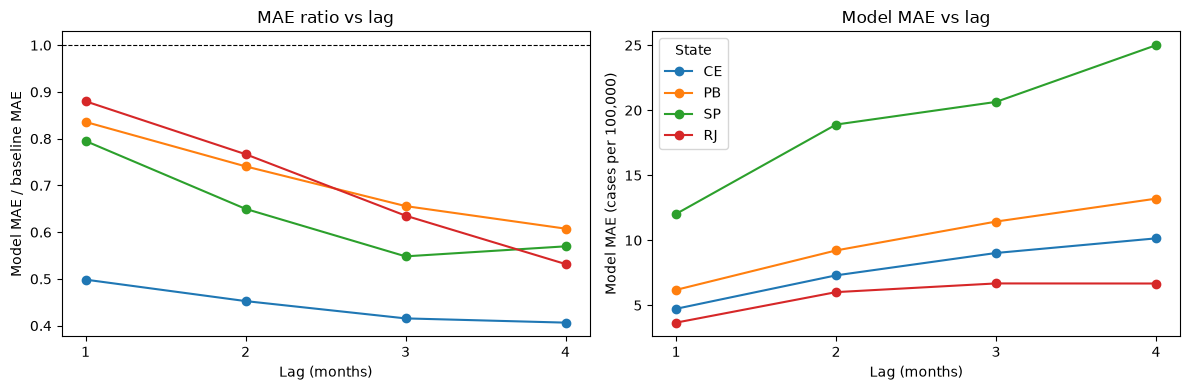

In [22]:
# MAE ratio and model MAE against lag, one line per state (all test years together); the translucent markers are the
# values in each test year separately.
# The baseline for lag k is "the rate k months ago", which gets worse as k grows. So a falling ratio can come from
# a worse baseline rather than a better model; the model's own MAE is plotted alongside to show which it is
lag_plot_df = (
    lag_comparison
    .with_columns(
        pl.col("model").str.extract(r"Lag (\d+)").cast(pl.Int64).alias("lag"),
        pl.col("state code").replace_strict(pf.CODE_TO_UF).alias("state"),
    )
    .sort("state", "lag")
)

fig, (ax_ratio, ax_mae) = plt.subplots(1, 2, figsize=(13, 4))
for state_name in SELECTED_STATES:
    s = lag_plot_df.filter(pl.col("state") == state_name)
    (line,) = ax_ratio.plot(s["lag"], s["mae_ratio"], marker="o", label=state_name)
    plot_yearly_values(ax_ratio, s["lag"], s, "mae_ratio", color=line.get_color())
    ax_mae.plot(s["lag"], s["model_mae"], marker="o", color=line.get_color(), label=state_name)
    plot_yearly_values(ax_mae, s["lag"], s, "model_mae", color=line.get_color())
ax_ratio.axhline(1, color="black", linewidth=0.8, linestyle="--")   # above this line = worse than the baseline
# log scale for ratios: 0.5 and 2 are the same distance from 1, and a single bad test year doesn't squash the rest
ax_ratio.set_yscale("log")
ax_ratio.set(xlabel="Lag (months)", ylabel="Model MAE / baseline MAE", title="MAE ratio vs lag (line: all test years)")
ax_mae.set(xlabel="Lag (months)", ylabel="Model MAE (cases per 100,000)", title="Model MAE vs lag (line: all test years)")
for ax in (ax_ratio, ax_mae):
    ax.set_xticks(sorted(lag_plot_df["lag"].unique()))
add_year_legend(ax_ratio, fontsize="small")
ax_mae.legend(title="State")
plt.tight_layout()
plt.show()

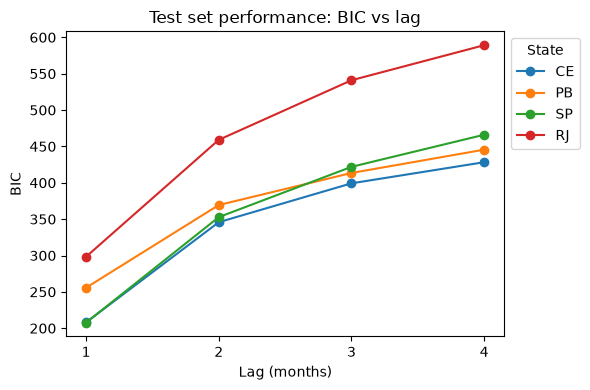

In [23]:
# BIC against lag, one line per state

fig, ax = plt.subplots(figsize=(6, 4))
for state_name in SELECTED_STATES:
    s = lag_plot_df.filter(pl.col("state") == state_name)
    ax.plot(s["lag"], s["bic"], marker="o", label=state_name)
ax.set(xlabel="Lag (months)", ylabel="BIC", title="BIC vs lag (training years)")
ax.set_xticks(sorted(lag_plot_df["lag"].unique()))
ax.legend(title="State", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

These plots suggest that a 1-month lag is probably best. The problem is that this only really allows me to predict one month in the future (well, more is possible, but the errors start to compound - so one month into the future at a reasonable performance) which is not very useful in practice.

Time series data is usually very autocorrelated; that is, the correlation between a variable and its lagged version is high. Given the context, it makes sense that, for example, yesterday's number of cases is going to have a much stronger relationship with today's number of cases than say, number of times I got 'heads' when flipping a coin yesterday vs today. This is because the number of cases today might be partly caused by yesterday's number of cases, which might be partly caused by the number of cases the day before, and so on. As the temporal lag increases, this relationship clearly becomes weaker.

In [24]:
# autocorrelation for log(rate)
from datetime import date
from statsmodels.tsa.stattools import acf

max_lag = 210 # days; covers the window considered for the monthly models

def compute_acf_by_state(daily_df, value_col, max_lag=max_lag):
    """Autocorrelation of value_col at lags 1..max_lag (days or weeks), one column per selected state. Needs one row
    per state per time step with no gaps: acf works on row positions, so a missing day would shift every later lag."""
    acf_by_state = dict()
    for state_name in SELECTED_STATES:
        values = daily_df.filter(pl.col("SG_UF_NOT") == pf.UF_ABBR_TO_CODE[state_name])[value_col].to_numpy()
        acf_by_state[state_name] = acf(values, nlags=max_lag)[1:] # drop lag 0 (always 1)
    return pl.DataFrame({"lag": np.arange(1, max_lag + 1), **acf_by_state})

def plot_acf_by_state(acf_df, n_obs, title, xlabel="Lag (days)"):
    """One line per state; the grey band is the approximate 95% range for zero autocorrelation (white noise).
    n_obs is the number of observations per state (days, or weeks for the weekly version)."""
    fig, ax = plt.subplots(figsize=(10, 5))
    for state_name in SELECTED_STATES:
        ax.plot(acf_df["lag"], acf_df[state_name], label=state_name)
    conf = 1.96 / np.sqrt(n_obs)
    ax.axhspan(-conf, conf, color="grey", alpha=0.2, label="95% band for no autocorrelation")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel="Autocorrelation", title=title)
    ax.legend()
    plt.show()

# ---- Daily log(rate) per state, training years only ----

all_days = pl.LazyFrame({
    "day": pl.date_range(date(int(TRAIN_YEARS[0]), 1, 1), date(pf.TRAIN_END_YEAR, 12, 31), interval="1d", eager=True)
})
n_train_days = all_days.select(pl.len()).collect().item()

daily_cases = (
    pl.concat([clean_dict[year] for year in TRAIN_YEARS])
    .group_by("SG_UF_NOT", pl.col("DT_NOTIFIC").alias("day"))
    .agg(pl.len().alias("cases"))
)

daily_log_rate = (
    pl.LazyFrame({"SG_UF_NOT": SELECTED_CODES})
    .join(all_days, how="cross")
    .join(daily_cases, on=["SG_UF_NOT", "day"], how="left")
    .with_columns(pl.col("cases").fill_null(0), pl.col("day").dt.year().alias("year"))
    .join(pop_lf, on=["SG_UF_NOT", "year"], how="left") # every year has a population: pf.fetch_population fills gaps
    # log1p (+1) is still needed here: unlike monthly totals, many single days have no notifications at all
    .with_columns((pl.col("cases") / pl.col("population") * 100_000).log1p().alias("log_rate"))
    .sort("SG_UF_NOT", "day")
    .collect()
)

acf_rate_df = compute_acf_by_state(daily_log_rate, "log_rate")

The regular spikes every 7 days most likely come from how cases are reported rather than from dengue itself: fewer notifications are filed at weekends, so each day of the week has its own typical level. Days a whole number of weeks apart fall on the same weekday and therefore look more alike than days in between, which gives the peaks at specific lags. Working at a coarser resolution than daily (weekly, as below, or monthly, as in the models) removes this weekday effect. The table after the plot checks these claims.

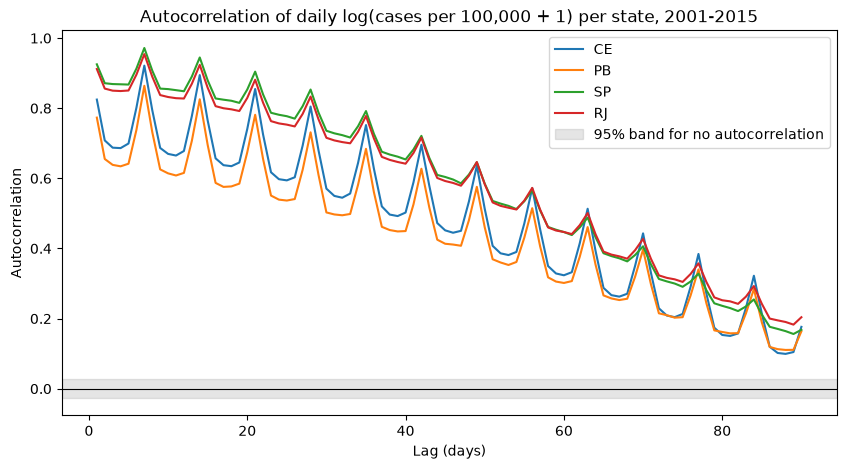

In [355]:
plot_acf_by_state(acf_rate_df, n_train_days,
                  f"Autocorrelation of daily log(cases per 100,000 + 1) per state, {TRAIN_YEARS[0]}-{pf.TRAIN_END_YEAR}")

In [ ]:
# Check of the claims above. 1) Average notifications per weekday, relative to that state's average day (1 = an average day):
weekday_table = (
    daily_log_rate
    .with_columns(pl.col("day").dt.weekday().alias("weekday_nr"), pl.col("day").dt.strftime("%a").alias("weekday"),
                  pl.col("SG_UF_NOT").replace_strict(pf.CODE_TO_UF).alias("state"))
    .group_by("state", "weekday_nr", "weekday")
    .agg(pl.col("cases").mean())
    .with_columns((pl.col("cases") / pl.col("cases").mean().over("state")).round(2))
    .pivot(on="state", index=["weekday_nr", "weekday"], values="cases")
    .sort("weekday_nr")
    .select("weekday", *SELECTED_STATES)
)
print(weekday_table)

# 2) the autocorrelation peaks at whole weeks (7, 14 days) and dips in between
acf_rate_df.filter(pl.col("lag").is_in([5, 6, 7, 8, 9, 13, 14, 15])).with_columns(pl.exclude("lag").round(3))

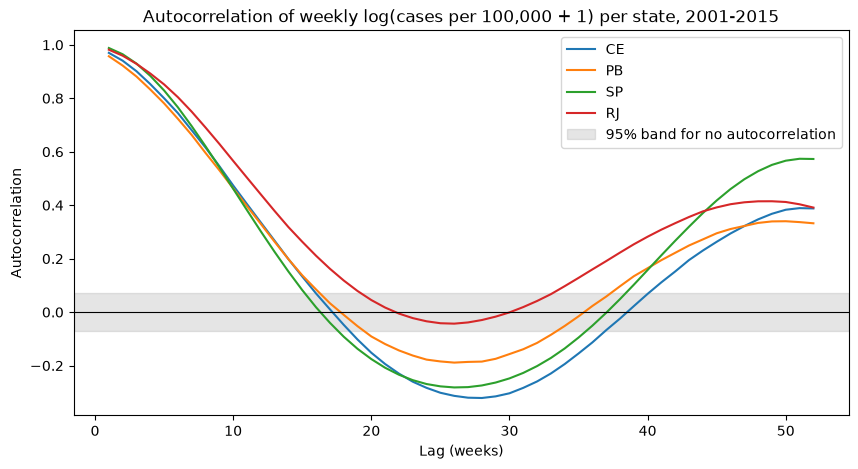

In [25]:
# Weekly version of the log(rate) autocorrelation, to check whether the plot looks less odd
max_lag_weeks = 52 # a full year, so the seasonal cycle can show up (low around half a year, back up near 52 weeks)

weekly_log_rate = (
    daily_log_rate
    .with_columns(pl.col("day").dt.truncate("1w").alias("week")) # weeks start on Monday
    .group_by("SG_UF_NOT", "week")
    .agg(pl.col("cases").sum(), pl.col("population").mean(), pl.len().alias("n_days"))
    .filter(pl.col("n_days") == 7) # drop the incomplete last week of the series
    .with_columns((pl.col("cases") / pl.col("population") * 100_000).log1p().alias("log_rate")) # same transform as daily; +1 still needed, PB and RJ have weeks with no cases
    .sort("SG_UF_NOT", "week")
)

acf_rate_weekly_df = compute_acf_by_state(weekly_log_rate, "log_rate", max_lag=max_lag_weeks)
plot_acf_by_state(acf_rate_weekly_df, weekly_log_rate.height // len(SELECTED_CODES),
                  f"Autocorrelation of weekly log(cases per 100,000 + 1) per state, {TRAIN_YEARS[0]}-{pf.TRAIN_END_YEAR}",
                  xlabel="Lag (weeks)")

Without the day-of-week effect the weekly autocorrelation is smooth. It is very high at short lags (0.96-0.99 after one week) and falls slowly, reaching zero after about 17-22 weeks (4-5 months). It is lowest around 26-28 weeks, ie half a year (a peak-season week compared with a low-season week), and rises again towards 52 weeks (0.33-0.57), which is the yearly seasonal cycle. RJ, whose low point barely goes below zero, has the weakest seasonal swing in this measure.

The ideal lag can't be read off this plot: every lag up to 3-4 months is strongly correlated, and the autocorrelation at lag k also contains the indirect link through all the lags in between, plus the shared seasonal pattern, so it doesn't show what a lag adds on top of the shorter ones. That is what the model comparison above (MAE ratio and BIC) is for; the plot only confirms that the most recent values carry the most information.

## Adding rain data
I know rainfall isn't a sole predictor of dengue, but it should be a fairly good one since mosquitoes breed in still water. I would like to know in particular whether rainfall adds any value beyond what my seasonal variable can capture.

In [357]:
spatiotemporal_rain_data = pf.load_rainfall_spatiotemporal() # get daily rainfall data + spatial information

In [358]:
# ---- Add monthly rainfall data ----
# Daily gauge readings -> monthly state-level value:
#   1. per gauge: mean daily rainfall in each month (mm/day), so gauges with missing days aren't penalised
#   2. per state: median across gauges, robust to the gauges with outlier values. The 25th and 75th percentiles
#      across gauges and the number of gauges are kept too, to show how much the gauges within a state disagree

monthly_rain = (
    pl.concat(list(spatiotemporal_rain_data.values()), how="vertical")
    .filter(pl.col("code_state").is_in(SELECTED_CODES))
    .with_columns(pl.col("datetime").dt.truncate("1mo").cast(pl.Date).alias("month"))
    .group_by("code_state", "gauge_code", "month")
    .agg(pl.col("rain_mm").mean().alias("gauge_rain"))
    .group_by("code_state", "month")
    .agg(
        pl.col("gauge_rain").median().alias("rain"),
        pl.col("gauge_rain").quantile(0.25).alias("rain_q25"),
        pl.col("gauge_rain").quantile(0.75).alias("rain_q75"),
        pl.len().alias("n_gauges"),
    )
    .rename({"code_state": "SG_UF_NOT"})
    .sort("SG_UF_NOT", "month")
)

In [ ]:
# Spread of the gauges within each state, month by month: median across gauges (line, the value used in the models),
# 25th-75th percentile across gauges (band), and the number of gauges with readings that month (grey, right axis)
monthly_rain_df = monthly_rain.collect()

fig, axes = plt.subplots(len(SELECTED_STATES), 1, figsize=(13, 2.6 * len(SELECTED_STATES)), sharex=True)
for ax, state_name in zip(axes, SELECTED_STATES):
    s = monthly_rain_df.filter(pl.col("SG_UF_NOT") == pf.UF_ABBR_TO_CODE[state_name])
    ax.fill_between(s["month"], s["rain_q25"], s["rain_q75"], alpha=0.35, label="25th-75th percentile across gauges")
    ax.plot(s["month"], s["rain"], linewidth=0.8, label="Median across gauges")
    ax.set(ylabel="Rain (mm/day)", title=state_name)
    ax_n = ax.twinx()
    ax_n.plot(s["month"], s["n_gauges"], color="grey", linewidth=1, linestyle="--", label="Number of gauges (right axis)")
    ax_n.set_ylabel("Gauges", color="grey")
    ax_n.set_ylim(bottom=0)
handles = axes[0].get_legend_handles_labels()[0] + ax_n.get_legend_handles_labels()[0]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.supxlabel("Month")
plt.tight_layout()
plt.show()

# summary per state: typical number of gauges, and the typical gap between the 25th and 75th percentile
(monthly_rain_df
    .group_by("SG_UF_NOT")
    .agg(pl.col("n_gauges").min().alias("min gauges"), pl.col("n_gauges").median().alias("median gauges"),
         pl.col("n_gauges").max().alias("max gauges"), pl.col("rain").median().alias("median rain (mm/day)"),
         (pl.col("rain_q75") - pl.col("rain_q25")).median().alias("median IQR (mm/day)"))
    .with_columns(pl.col("SG_UF_NOT").replace_strict(pf.CODE_TO_UF).alias("state"), cs.float().round(2))
    .sort("SG_UF_NOT")
    .select("state", pl.exclude("state", "SG_UF_NOT")))

The gauges within a state disagree a lot. In CE and PB the typical gap between the 25th and 75th percentile (1.3-1.8 mm/day) is about twice the typical monthly median (0.6-0.9 mm/day), and the band is widest in the wet season in every state. The number of gauges is also uneven: RJ has by far the fewest (about 100 a month, with a short spike in 2015), against about 250 in PB and 540-650 in CE and SP, and in CE the number drops from about 600 to 450-500 between roughly 2009 and 2016. So the median rain used in the models is a noisier summary in some states and periods than in others, which may be one more reason why rain adds little beyond the seasonal terms.

### Checking autocorrelation
Autocorrelation tells us how much the value at a timepoint $t-n$ influences the reading at $t$, where $n$ is a lag value (eg, $n$ days before). This can be useful for knowing which lag values to choose.


In [359]:
# ---- Autocorrelation of daily rainfall per state, training years only ----
# Daily state-level value = trimmed mean across the state's gauges.
# The median used for monthly_rain doesn't work daily: rain is patchy, so most gauges read 0 on most days
# (the median is 0 on ~94% of days in CE). A plain mean is wrecked by broken gauges (eg 65,953 mm in one day in SP),
# so readings above each state-day's 99th percentile across gauges are dropped before averaging.
# Reuses compute_acf_by_state, plot_acf_by_state and n_train_days from the log(rate) autocorrelation cells above.
daily_rain = (
    pl.concat(list(spatiotemporal_rain_data.values()), how="vertical")
    .filter(
        pl.col("code_state").is_in(SELECTED_CODES),
        pl.col("datetime").dt.year() <= pf.TRAIN_END_YEAR,
    )
    .with_columns(pl.col("datetime").cast(pl.Date).alias("day"))
    .filter(pl.col("rain_mm") <= pl.col("rain_mm").quantile(0.99).over("code_state", "day"))
    .group_by("code_state", "day")
    .agg(pl.col("rain_mm").mean().alias("rain"))
    .rename({"code_state": "SG_UF_NOT"})
    .sort("SG_UF_NOT", "day")
    .collect()
)

# the rain data doesn't go through pf.full_basic_clean, so check that no state is missing days
# (compute_acf_by_state relies on one row per day)
assert (daily_rain.group_by("SG_UF_NOT").len()["len"] == n_train_days).all(), "a state is missing days of rain data"

acf_df = compute_acf_by_state(daily_rain, "rain")

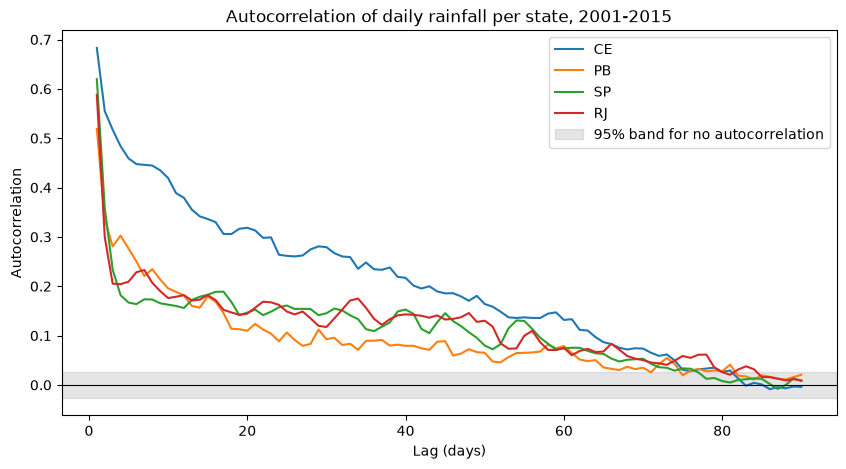

In [360]:
plot_acf_by_state(acf_df, n_train_days, f"Autocorrelation of daily rainfall per state, {TRAIN_YEARS[0]}-{pf.TRAIN_END_YEAR}")

A lag of more than 20 days doesn't seem to add much information for states PB, SP and RJ, whereas for CE it's more around 60 days that it starts to have an autocorrelation comparable with the other states, and is therefore less informative. We are only working at the monthly resolution at the moment. This is for two reasons: one, computational simplicity, and two, because seasonal patterns occur over pretty large timescales, so it seems reasonable to make this simplification given the context.

So for states PB, SP and RJ, just from eyeballing the plot I would say a lag of 1 (month) is most reasonable, whereas for CE a lag of 2 months may work best. I will also check what happens if I sum the rain values rather than just have them as individual predictors.

In [ ]:
from functools import reduce

def compute_model_df_rain(model_df, monthly_rain, max_lag=1, sum=False, drop_nulls=True):
    """Add the state's rain 1 to max_lag months earlier (rain_lag1 ...) to model_df, plus their sum (rain_sum{max_lag}) if sum=True.
    drop_nulls=True drops rows missing any lag, so all models fitted on the result use the same rows (needed to compare them)."""
    lag_cols = [f"rain_lag{k}" for k in range(1, max_lag + 1)]

    # shift the full rain series before joining, so the first months of model_df can still get earlier rain
    rain_lagged = (
        monthly_rain
        .sort("SG_UF_NOT", "month")
        .with_columns([pl.col("rain").shift(k).over("SG_UF_NOT").alias(f"rain_lag{k}") for k in range(1, max_lag + 1)])
    )
    if sum:
        # adding with + keeps the sum missing if any lag is missing (pl.sum_horizontal would treat missing as 0),
        # see the markdown below
        rain_lagged = rain_lagged.with_columns(
            reduce(lambda a, b: a + b, [pl.col(c) for c in lag_cols]).alias(f"rain_sum{max_lag}")
        )

    lf = model_df.join(rain_lagged, on=["SG_UF_NOT", "month"], how="left")
    if drop_nulls:
        lf = lf.drop_nulls(lag_cols)
    return lf

**Why the lags are added with `+` rather than `pl.sum_horizontal`.** If one of the lagged months has no rain value (eg the first months of the series, which have no earlier month to shift in, or a month without any gauge readings), `+` makes the sum missing too, whereas `pl.sum_horizontal` skips missing values, ie counts that month as 0 mm. The sum would then look like a drier period than it really was, and the row would stay in the model with a value that is too low. With `drop_nulls=True`, as used below, those rows are dropped anyway because their individual lag columns are missing, so here the choice makes no difference; it matters when `drop_nulls=False`, where it keeps the sum honest (missing rather than too low).

In [362]:
# Compare ways of adding rain to the model. All models use the same rows (one model_df_rain),
# no-rain model included as the reference
max_rain_lag = 3
model_df_rain = compute_model_df_rain(model_df, monthly_rain, max_lag=max_rain_lag, sum=True)

rain_predictors = {
    "no rain": "",
    **{f"lag {k}": f"rain_lag{k}" for k in range(1, max_rain_lag + 1)},
    "all lags": " + ".join(f"rain_lag{k}" for k in range(1, max_rain_lag + 1)),
    f"sum of lags 1-{max_rain_lag}": f"rain_sum{max_rain_lag}",
}

rain_results = dict()
for state in SELECTED_STATES:
    state_code = pf.UF_ABBR_TO_CODE[state]
    for label, rain_terms in rain_predictors.items():
        formula = "log_rate ~ log_rate_lag + sin_m + cos_m" + (f" + {rain_terms}" if rain_terms else "")
        rain_results[f"state {state}: {label}"] = run_improved_regression(state_code, model_df_rain, formula=formula)

Running regression for state  23
Running regression for state  23
Running regression for state  23
Running regression for state  23
Running regression for state  23
Running regression for state  23
Running regression for state  25
Running regression for state  25
Running regression for state  25
Running regression for state  25
Running regression for state  25
Running regression for state  25
Running regression for state  35
Running regression for state  35
Running regression for state  35
Running regression for state  35
Running regression for state  35
Running regression for state  35
Running regression for state  33
Running regression for state  33
Running regression for state  33
Running regression for state  33
Running regression for state  33
Running regression for state  33


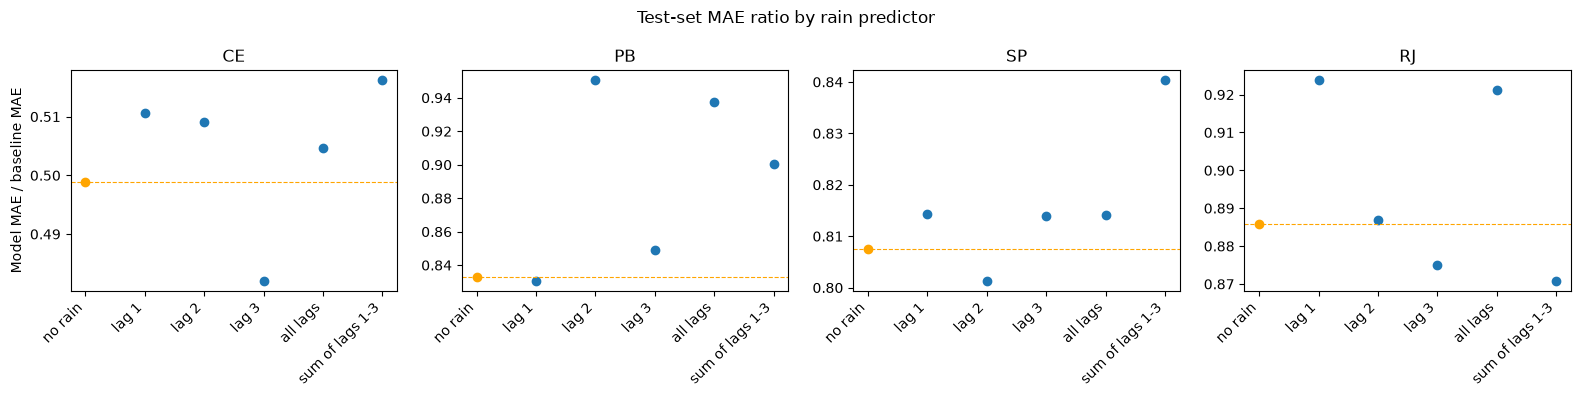

In [363]:
rain_comparison = compare_models(rain_results)

rain_plot_df = rain_comparison.with_columns(
    pl.col("model").str.split(": ").list.get(1).alias("rain predictor"),
    pl.col("state code").replace_strict(pf.CODE_TO_UF).alias("state"),
)

predictor_order = list(rain_predictors)   # same order as defined above, starting with the no-rain reference

def plot_rain_predictors_by_state(plot_df, value_col, ylabel, title, yearly=False):
    """One subplot per state with value_col per rain predictor, each state with its own y-axis (the point is to compare predictors
    within a state). Dashed line = the no-rain model; yearly=True adds the per-test-year MAE ratios as translucent markers."""
    x = np.arange(len(predictor_order))
    is_no_rain = np.array(predictor_order) == "no rain"
    fig, axes = plt.subplots(1, len(SELECTED_STATES), figsize=(4 * len(SELECTED_STATES), 4))
    for ax, state_name in zip(axes, SELECTED_STATES):
        # one row per predictor, in predictor_order, so the rows line up with x
        s = pl.DataFrame({"rain predictor": predictor_order}).join(
            plot_df.filter(pl.col("state") == state_name), on="rain predictor", how="left", maintain_order="left")
        values = s[value_col].to_numpy()
        # categories, not a scale, so no connecting lines; the no-rain reference is orange to match its dashed line
        ax.plot(x[~is_no_rain], values[~is_no_rain], marker="o", linestyle="none", color="C0")
        ax.plot(x[is_no_rain], values[is_no_rain], marker="o", linestyle="none", color="orange")
        ax.axhline(values[is_no_rain][0], color="orange", linewidth=0.8, linestyle="--")
        if yearly:
            plot_yearly_values(ax, x[~is_no_rain], s.filter(pl.Series(~is_no_rain)), "mae_ratio", color="C0")
            plot_yearly_values(ax, x[is_no_rain], s.filter(pl.Series(is_no_rain)), "mae_ratio", color="orange")
            ax.set_yscale("log") # ratios: 0.5 and 2 are the same distance from 1
            ax.yaxis.set_major_formatter(plt.ScalarFormatter()) # plain numbers instead of eg 6x10^-1
            ax.yaxis.set_minor_formatter(plt.NullFormatter())
        ax.set_xticks(x, predictor_order, rotation=45, ha="right")
        ax.set_title(state_name)
    axes[0].set_ylabel(ylabel)
    if yearly:
        add_year_legend(axes[-1], loc="upper left", bbox_to_anchor=(1, 1))
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_rain_predictors_by_state(rain_plot_df, "mae_ratio", "Model MAE / baseline MAE",
                              "Test-set MAE ratio by rain predictor (solid markers: all test years)", yearly=True)

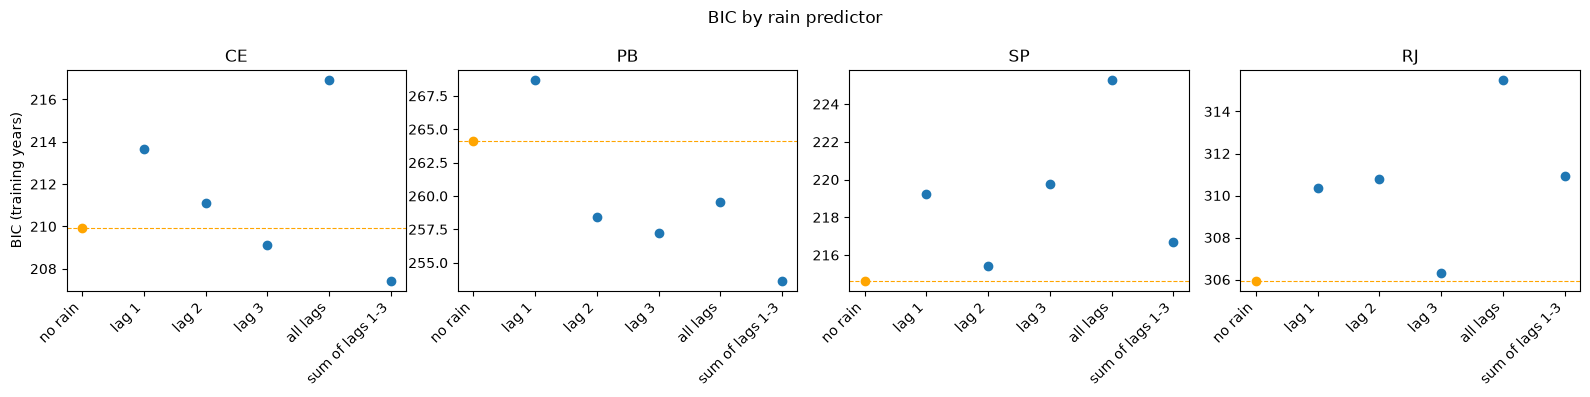

In [ ]:
# Same layout for BIC
plot_rain_predictors_by_state(rain_plot_df, "bic", "BIC (training years)",
                              "BIC by rain predictor")

In [365]:
# For a single state (SP): correlation between the lagged log rate, the seasonal terms, and the rain predictor
# that performed best for SP. "Best" uses the test-set MAE ratio, like the plot above; set selection_metric to
# "bic" to choose on the training years instead, which avoids using the test set for this choice
example_state = "SP"
selection_metric = "mae_ratio"

best_predictor = (
    rain_plot_df
    .filter(pl.col("state") == example_state, pl.col("rain predictor") != "no rain")
    .sort(selection_metric)["rain predictor"][0]
)
best_rain_cols = rain_predictors[best_predictor].split(" + ")
print(f"Best rain predictor for {example_state} by {selection_metric}: {best_predictor} ({', '.join(best_rain_cols)})")

train, test, fit = rain_results[f"state {example_state}: {best_predictor}"]
train[["log_rate_lag"] + best_rain_cols + ["sin_m", "cos_m"]].corr()

Best rain predictor for SP by mae_ratio: lag 2 (rain_lag2)


,log_rate_lag,rain_lag2,sin_m,cos_m
log_rate_lag,1.000000,0.342079,0.452518,-0.596691
rain_lag2,0.342079,1.000000,0.812976,0.035169
sin_m,0.452518,0.812976,1.000000,-0.009994
cos_m,-0.596691,0.035169,-0.009994,1.000000


Since the sum of rainfall readings and the seasonality sinusoid are heavily correlated, it is not really surprising that the rainfall data doesn't contribute much to performance, as most of its information is probably already accounted for.

# Trying to detangle seasonal patterns
With relatively weak predictive power, maybe the best thing to do is try to understand what are normal seasonal patterns in dengue cases and which part is unrelated to seasonality. This could be helpful in determining which years can be considered epidemics, for example.

> Since this is purely descriptive we can use the entire dataset.

The method was taken from [Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, ch. 3](https://otexts.com/fpp3/decomposition.html) as it seemed to balance simplicity and usefulness quite well. The chapter advises against classical decomposition and suggests STL as a more versatile option; the seasonal pattern can change slowly over the years and it can be made robust to outliers. Key choices:
- **Windows: the chapter's defaults** (seasonal window 11 years, trend window 21 months for monthly data). I checked other seasonal windows (7 and 21) and the strength of seasonality changes little, so the conclusions don't depend on this choice.
- **Robust fitting.** Epidemic months are exactly the "occasional unusual observations" that robust STL keeps out of the trend and seasonal components; without it, part of every epidemic would be counted as normal seasonality.
- **Multiplicative, via a log transform.** A multiplicative decomposition is appropriate when the seasonal variation is proportional to the level of the series. The check in the next cell confirms this: on the raw scale, each year's seasonal swing tracks that year's level almost perfectly, while after a log transform the link is much weaker. STL itself is additive only, so, as the chapter suggests, it is applied to $\log(\text{rate})$, which makes it a multiplicative decomposition of the rate. To keep months with zero cases (Paraná has one) on the log scale, half a case is added first: $\log\left(\frac{\text{cases} + 0.5}{\text{population}}\right)$. Half a case is negligible except in near-empty months (the regression models use a plain log instead, which works because none of the four main states has a month without cases): for the four main states it changes the strength measures by at most 0.002.

The share of variation explained is summarised with the strength of seasonality and of trend as defined by section 4.3: 
$$F_S = \max\left(0,\ 1 - \frac{\text{Var}(R)}{\text{Var}(S + R)}\right)$$

and the same with the trend in place of $S$. Values close to 1 mean the component dominates the remainder; close to 0 means there is barely any seasonality (or trend).

> Trend window: To estimate the trend at a given month, STL averages the surrounding consecutive months. A trend window of 21 means 10 months before, the month itself, and 10 months after.

When you leave it out, statsmodels calculates it with the rule from the original STL paper, which ends up being 21 with a window of 11.

In [26]:
from scipy import stats

def prepare_stl_data(monthly_counts):
    """Monthly counts (from pf.cases_per_capita_monthly) -> one row per state and month in time order, as STL needs,
    with log_rate = log((cases + 0.5) / population * 100,000); the half case keeps zero months on the log scale."""
    return (
        monthly_counts
        .with_columns(
            ((pl.col("cases") + 0.5) / pl.col("population") * 100_000).log().alias("log_rate"),
            pl.col("month").dt.year().alias("year"),
        )
        .sort("SG_UF_NOT", "month")
        .collect()
    )

stl_data = prepare_stl_data(monthly_case_counts)

# Check properly whether it is appropriate to take an additive approach
yearly = stl_data.group_by("SG_UF_NOT", "year").agg(
    pl.col("rate").mean().alias("level_raw"), (pl.col("rate").max() - pl.col("rate").min()).alias("swing_raw"),
    pl.col("log_rate").mean().alias("level_log"), (pl.col("log_rate").max() - pl.col("log_rate").min()).alias("swing_log"),
)
for state_name in SELECTED_STATES:
    d = yearly.filter(pl.col("SG_UF_NOT") == pf.UF_ABBR_TO_CODE[state_name])
    print(f"{state_name}: swing vs level, rho raw = {stats.spearmanr(d['level_raw'], d['swing_raw'])[0]:.2f}, "
          f"rho log = {stats.spearmanr(d['level_log'], d['swing_log'])[0]:.2f}")

CE: swing vs level, rho raw = 0.95, rho log = 0.21
PB: swing vs level, rho raw = 0.92, rho log = 0.17
SP: swing vs level, rho raw = 0.99, rho log = 0.26
RJ: swing vs level, rho raw = 0.99, rho log = 0.59


In [27]:
import pandas as pd
from statsmodels.tsa.seasonal import STL

def run_stl(state_code, seasonal_window=11, robust=True, data=None):
    """STL of log(monthly rate) for one state; data is from prepare_stl_data (default stl_data, the selected states).
    period=12: one cycle per year. The trend window is left to statsmodels: 21 months with seasonal_window=11, as in FPP3."""
    data = stl_data if data is None else data
    d = data.filter(pl.col("SG_UF_NOT") == state_code)
    log_rate = pd.Series(d["log_rate"].to_numpy(), index=pd.DatetimeIndex(d["month"].to_numpy()))
    return STL(log_rate, period=12, seasonal=seasonal_window, robust=robust).fit()

def component_strength(stl_fit, component):
    """FPP3 strength measure: 1 - Var(remainder) / Var(component + remainder), floored at 0."""
    return max(0.0, 1 - np.var(stl_fit.resid) / np.var(component + stl_fit.resid))

**Why `robust=True`?** STL estimates the trend and seasonal components with loess, a weighted average of nearby points. With `robust=True`, statsmodels repeats the fit several times: after each fit it looks at the remainder and gives every month a weight that gets smaller the larger that month's remainder is compared with a typical one (a 'bisquare' weight, which drops to 0 for a remainder more than 6 times the median absolute remainder). The next fit uses these weights, so months that don't follow the usual pattern have little influence on the trend and seasonal components, and their unusual part ends up in the remainder instead.

This matters here because dengue epidemics are exactly such months: a few months with rates many times higher than usual. Without robust fitting, an epidemic would partly be absorbed into the seasonal pattern of the surrounding years (making a normal season look bigger than it is) and into the trend. With the chosen settings (see below), between 14 (PB) and 27 (CE) of the 228 months per state get a weight below 0.5, and 6-12 per state get a weight of 0 (see `stl_results[state].weights`). As a result the seasonal and trend strengths are somewhat lower than without robust fitting (eg RJ seasonal strength 0.58 instead of 0.75), because these months' deviations now count as remainder. That is the intended behaviour: the seasonal component describes a normal year, and the epidemics show up in the remainder.

In [28]:
# try with default according to statsmodel's default (7), then try with the default recommended by the book I was following (11), then try
# a few other values around that
summaries = []
for window in [3, 7, 11, 15, 19]:
    results = {state_name: run_stl(pf.UF_ABBR_TO_CODE[state_name], seasonal_window=window) for state_name in SELECTED_STATES}
    summary = pl.DataFrame([
        {
            "state": state_name,
            "window size": window,
            "seasonal_strength": component_strength(fit, fit.seasonal),
            "trend_strength": component_strength(fit, fit.trend),
            "peak_to_trough_factor": float(np.exp(np.ptp(fit.seasonal.groupby(fit.seasonal.index.month).mean()))),
        }
        for state_name, fit in results.items()
    ])
    summaries.append(summary)

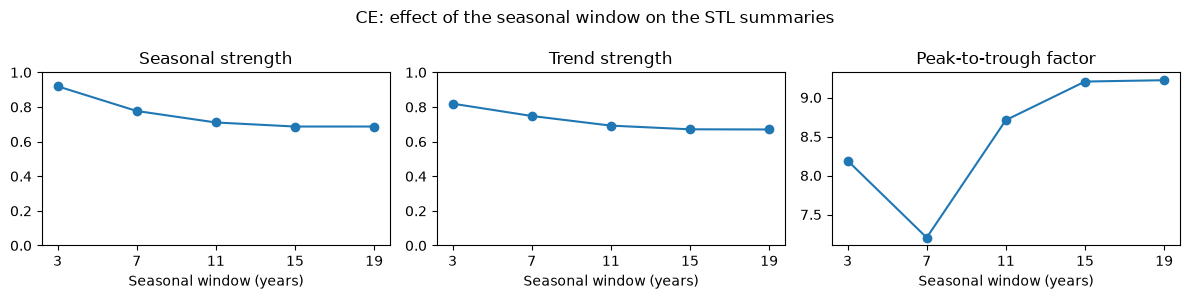

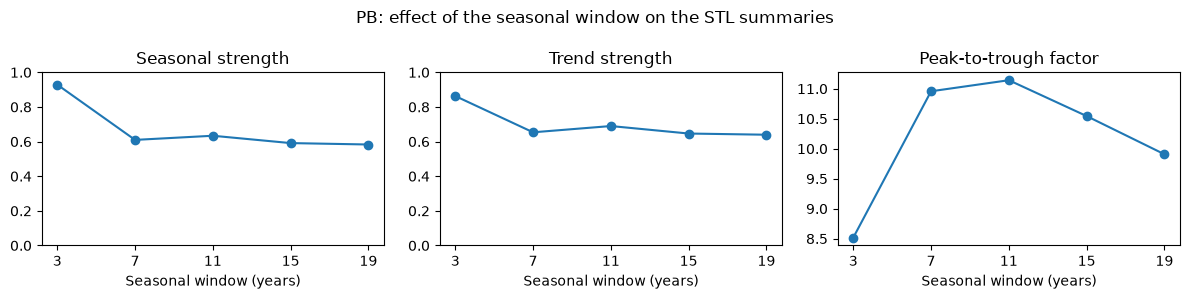

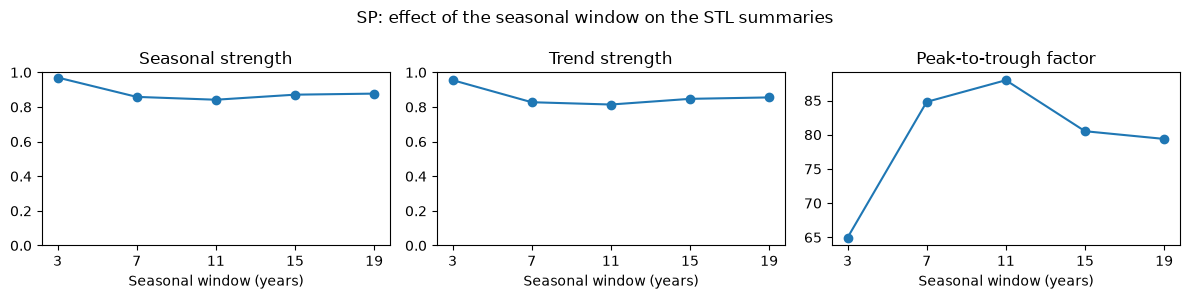

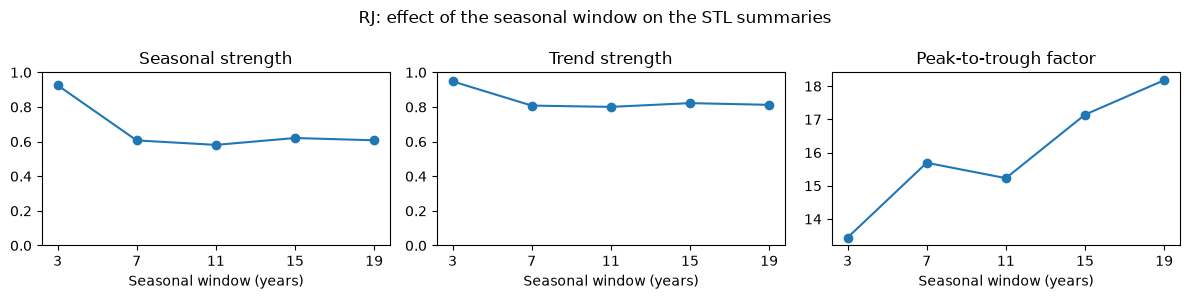

In [29]:
window_comparison = pl.concat(summaries, how="vertical") # the table from the cell above

def plot_window_effect(state_name, chosen_window=11):
    """For one state: seasonal strength, trend strength and peak-to-trough factor against the seasonal window.
    The strengths are drawn on their full 0-1 range, so the size of any change is not magnified."""
    s = window_comparison.filter(pl.col("state") == state_name).sort("window size")
    metrics = [("seasonal_strength", "Seasonal strength"), ("trend_strength", "Trend strength"),
               ("peak_to_trough_factor", "Peak-to-trough factor")]
    fig, axes = plt.subplots(1, len(metrics), figsize=(12, 3))
    for ax, (col, label) in zip(axes, metrics):
        ax.plot(s["window size"], s[col], marker="o")
        ax.set(xlabel="Seasonal window (years)", title=label)
        ax.set_xticks(s["window size"].to_list())
        if col.endswith("strength"):
            ax.set_ylim(0, 1)
    fig.suptitle(f"{state_name}: effect of the seasonal window on the STL summaries")
    plt.tight_layout()
    plt.show()

for state_name in SELECTED_STATES:
    plot_window_effect(state_name)

In [30]:
# I decided to go with a seasonal window of 11 years then since it's used for the original paper and the result seems to stabilize
# around this value anyway
stl_results = {state_name: run_stl(pf.UF_ABBR_TO_CODE[state_name]) for state_name in SELECTED_STATES}

# peak / trough factor: the decomposition is on the log scale, so exp(max - min) of the average seasonal
# pattern is how many times higher the rate is in the peak month than in the lowest month, all else equal
stl_strength = pl.DataFrame([
    {
        "state": state_name,
        "seasonal_strength": component_strength(fit, fit.seasonal),
        "trend_strength": component_strength(fit, fit.trend),
        "peak_to_trough_factor": float(np.exp(np.ptp(fit.seasonal.groupby(fit.seasonal.index.month).mean()))),
    }
    for state_name, fit in stl_results.items()
])
stl_strength

state,seasonal_strength,trend_strength,peak_to_trough_factor
str,f64,f64,f64
"""CE""",0.710422,0.692278,8.710317
"""PB""",0.633807,0.689843,11.142323
"""SP""",0.841822,0.814123,87.965535
"""RJ""",0.581023,0.800489,15.229286


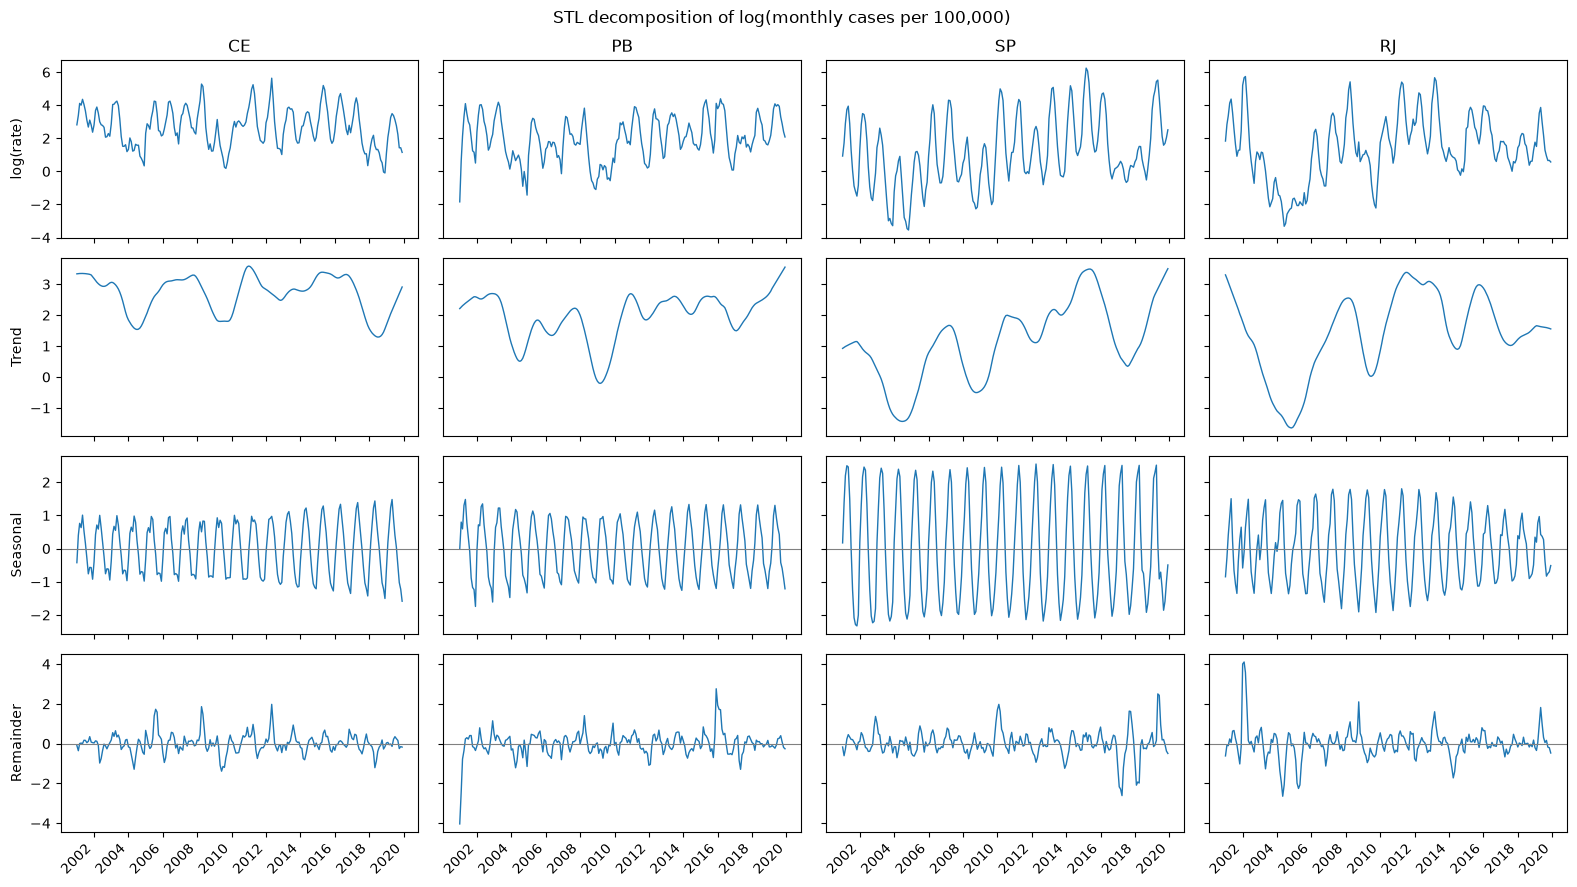

In [31]:
components = [("observed", "log(rate)"), ("trend", "Trend"), ("seasonal", "Seasonal"), ("resid", "Remainder")]

def draw_stl_components(fit, axes):
    """Draw the four STL components of one fit onto four axes (one per component, top to bottom)."""
    for ax, (attr, label) in zip(axes, components):
        series = getattr(fit, attr)
        ax.plot(series.index, series.values, linewidth=1)
        if attr in ("seasonal", "resid"):
            ax.axhline(0, color="grey", linewidth=0.8)

# One column per state, one row per component. sharey="row" puts each component on the same scale across
# states, so eg the size of the seasonal swings can be compared directly between states
fig, axes = plt.subplots(len(components), len(SELECTED_STATES), figsize=(4 * len(SELECTED_STATES), 9),
                         sharex=True, sharey="row")
for col, state_name in enumerate(SELECTED_STATES):
    draw_stl_components(stl_results[state_name], axes[:, col])
    axes[0, col].set_title(state_name)
for row, (attr, label) in enumerate(components):
    axes[row, 0].set_ylabel(label)

fig.autofmt_xdate(rotation=45)
fig.suptitle(f"STL decomposition of log(monthly cases per 100,000)")
plt.tight_layout()
plt.show()

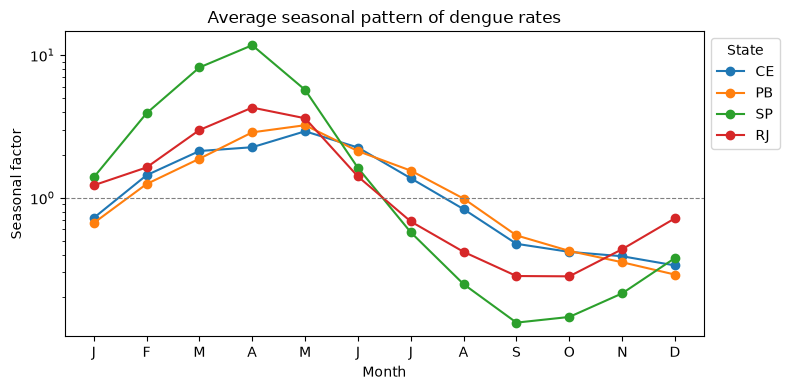

In [33]:
def plot_seasonal_factors(stl_fits, title):
    """Average seasonal pattern of each state as multiplicative factors (see the explanation below the plot).
    stl_fits: dict of {state_name: STL fit}. Log y-axis so that x2 and x0.5 are the same distance from 1."""
    fig, ax = plt.subplots(figsize=(8, 4))
    for state_name, fit in stl_fits.items():
        monthly_factor = np.exp(fit.seasonal.groupby(fit.seasonal.index.month).mean())
        ax.plot(monthly_factor.index, monthly_factor.values, marker="o", label=state_name)
    ax.axhline(1, color="grey", linewidth=0.8, linestyle="--")
    ax.set_yscale("log")
    ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
    ax.set(xlabel="Month", ylabel="Seasonal factor", title=title)
    ax.legend(title="State", loc="upper left", bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.show()

plot_seasonal_factors(stl_results, "Average seasonal pattern of dengue rates")

The **seasonal factor** says how many times higher (or lower) the rate is in a given month than in an average month, once the trend and the unusual deviations (the remainder) are taken out; 1 means an average month. Since the decomposition is on the log scale, it is the exponential of the seasonal component, averaged over the years for each calendar month.

All four states have one dengue season a year, but with different timing and strength:
- **SP and RJ** peak in April (factors 11.7 and 4.5), rising from February, and are lowest in September (0.13 and 0.29). The season is very pronounced in SP, where April has about 90 times the rate of September.
- **CE and PB** peak a month later, in May (3.0 and 3.3), stay high from March to June and are lowest in December (0.34 and 0.29): a flatter season, with a difference of about 9-11 times between the highest and the lowest month.

In all four states the peak comes a few months after the peak of the rainy season (around March-April in CE and PB, December-January in SP and RJ, see the rainfall plots).

The plot only shows the average pattern, and there is a lot of spread around it, in two ways. First, the seasonal pattern changes slowly over the years: eg the April factor in RJ ranges from 2.6 to 6.1 depending on the year, and the May factor in CE from 2.3 to 4.4, while SP's April peak is more stable (10.3-12.8). Second, single months deviate from trend x season by the remainder: in 90% of months the remainder is between about 0.35-0.5 and 2-2.5 times (a typical deviation of x1.6 in CE up to x2.2 in RJ). So the seasonal pattern describes *when* the season happens, much less how big a particular year's epidemic will be.

### Adding the state of Paraná back in
Just for fun, I decided to add Paraná back in, to see if it also had an obvious seasonal pattern.

In [ ]:
# Parana (PR) is not in SELECTED_STATES, so its monthly counts are built the same way as monthly_case_counts,
# then go through the same STL functions as the other states
pr_code = pf.UF_ABBR_TO_CODE["PR"]
pr_monthly_counts = pl.concat(
    [pf.cases_per_capita_monthly(lf, pop_lf, year, states=[pr_code]) for year, lf in clean_dict.items()],
    how="vertical",
)
pr_fit = run_stl(pr_code, data=prepare_stl_data(pr_monthly_counts))

plot_seasonal_factors({**stl_results, "PR": pr_fit}, "Average seasonal pattern of dengue rates, including Parana")

From the rainfall data, I assumed maybe due to some climate-related reason there might be no obvious seasonal rainfall pattern, but of course it could also be a data quality issue (which in fact, seems more plausible...). The state shows a strong seasonal pattern like the others.

---
## Subtracting seasonality
To get what the resource mentioned earlier refers to as the seasonally-adjusted series, the seasonal component is removed from the data. Because the decomposition was done on log(rate), this is log(rate) minus the seasonal component, which leaves trend + remainder. On the original scale it means dividing each month's rate by that month's seasonal factor: if March is usually twice as high as an average month, a March rate is halved.

What is left shows whether a month is high or low *for that time of year*, so months from different seasons can be compared directly. This is what makes it useful here: a peak-season month is always high, but it only stands out in the seasonally adjusted series if it is higher than a normal peak, which is a simple way to spot epidemic years. The chapter's caveat is that the adjusted series still contains the remainder, so it is not smooth; to look at the long-term direction, the trend component is the better choice.

In [ ]:
# Seasonally adjusted series for the four selected states (stl_results, so Parana is left out again).
# STL splits log(rate) into trend + seasonal + remainder, so removing the seasonal part leaves trend + remainder.
# Back on the rate scale this is the rate divided by that month's seasonal factor
adjusted = pl.concat([
    pl.DataFrame({
        "state": state_name,
        "month": fit.observed.index.to_numpy().astype("datetime64[ms]"), # polars needs ms, us or ns
        "rate": np.exp(fit.observed.to_numpy()),
        "adjusted_rate": np.exp((fit.observed - fit.seasonal).to_numpy()),
    })
    for state_name, fit in stl_results.items()
]).with_columns(pl.col("month").dt.year().alias("year"), pl.col("month").dt.month().alias("calendar_month"))

# observed (grey) and seasonally adjusted (colour) rate over time, log scale like the decomposition
fig, axes = plt.subplots(len(SELECTED_STATES), 1, figsize=(12, 2.4 * len(SELECTED_STATES)), sharex=True)
for ax, state_name in zip(axes, SELECTED_STATES):
    s = adjusted.filter(pl.col("state") == state_name)
    ax.plot(s["month"], s["rate"], color="lightgrey", linewidth=1, label="Observed")
    ax.plot(s["month"], s["adjusted_rate"], linewidth=1, label="Seasonally adjusted")
    ax.set_yscale("log")
    ax.set_title(state_name)
axes[0].legend(loc="upper left")
fig.supylabel("Cases per 100,000 (log scale)")
fig.supxlabel("Month")
plt.tight_layout()
plt.show()

In [ ]:
# Distribution of the seasonally adjusted rate within each year: one box per year (12 months each), so years that are
# high or unusually variable once the normal season is removed stand out
fig, axes = plt.subplots(1, len(SELECTED_STATES), figsize=(4.5 * len(SELECTED_STATES), 4), sharey=True)
years = sorted(adjusted["year"].unique().to_list())
for ax, state_name in zip(axes, SELECTED_STATES):
    s = adjusted.filter(pl.col("state") == state_name)
    ax.boxplot([s.filter(pl.col("year") == year)["adjusted_rate"].to_numpy() for year in years], tick_labels=years)
    ax.set_yscale("log")
    ax.tick_params(axis="x", labelrotation=90)
    ax.set_title(state_name)
axes[0].set_ylabel("Seasonally adjusted cases per 100,000 (log scale)")
fig.supxlabel("Year")
plt.tight_layout()
plt.show()

# check that the seasonality is gone: how far apart the calendar months are on average (ratio of the highest to the
# lowest monthly median), before and after the adjustment
(adjusted
    .group_by("state", "calendar_month")
    .agg(pl.col("rate", "adjusted_rate").median())
    .group_by("state")
    .agg((pl.col("rate").max() / pl.col("rate").min()).round(1).alias("highest / lowest month, observed"),
         (pl.col("adjusted_rate").max() / pl.col("adjusted_rate").min()).round(1).alias("highest / lowest month, adjusted"))
    .sort("state"))

After removing the seasonal pattern the calendar months are close to each other (the highest monthly median is 1.2-2.1 times the lowest, against 11-76 times before), so the seasonality has been removed and what is left is the trend plus unusual months. The years with the highest seasonally adjusted rates are the known epidemic years: 2015 in SP (followed by 2019 and 2014), 2011 in RJ, 2015-2016 and 2001 in CE, and 2019 and 2015 in PB. The boxplots also show that in an epidemic year the adjusted rate is high for several months rather than one, and that some years are far below a normal year even after the adjustment, eg 2017-2018 in SP, which matches the poor MAE ratios for SP in 2017 (see the plots of the yearly ratios above).